# 🌲 TERRA-FIRE: Predictive Wildfire Intelligence Engine
## Activity 5. Variable Impact Analysis
**Institution:** Universidad Tecnológica El Retoño (UTR)  
**Major:** Information Technologies and Digital Innovation Engineering  
**Subject:** Data Science (`LITD9A`) — Term: Sep–Dec 2026  
**Teacher:** Dr. Sergio Valadez Godínez  
**Authors:** Angel Emilio Gutierrez Lozano (ID: 4341) & Emiliano Betanzos Valtierra (ID: 4795)  
**Date:** October 20, 2026  
**Analysis-Ready Artifact:** `data/processed/terra_fire_spatiotemporal_matrix_v1.parquet` (18,275 observations × 22 attributes)

---
### 🎯 Activity Objective
To identify, quantify, and interpret statistical relationships among thermodynamic, biophysical, topographic, and anthropogenic variables through **Pearson and Spearman correlation analysis**, **simple linear and empirical probability regression analysis**, **inferential hypothesis testing (95% CI, $t$-statistics, $p$-values)**, and **Variance Inflation Factor (VIF) multicollinearity diagnostics** to determine which variables exert the highest explanatory impact on 48–72h wildfire ignitions (`fire_ignition_48h`).


In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

DATA_PATH = '../data/processed/terra_fire_spatiotemporal_matrix_v1.parquet'
if not os.path.exists(DATA_PATH):
    DATA_PATH = '/home/eduardo/Workspaces/TERRA-FIRE/TERRA-FIRE/data/processed/terra_fire_spatiotemporal_matrix_v1.parquet'

df = pd.read_parquet(DATA_PATH)
print(f"[LOAD] Immutable Analysis-Ready Dataset verified: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"[INTEGRITY] Remaining Missing Values: {df.isnull().sum().sum()} | Positive Ignitions (1): {df['fire_ignition_48h'].sum()} ({df['fire_ignition_48h'].mean()*100:.2f}%)")

[LOAD] Immutable Analysis-Ready Dataset verified: 18,275 rows × 22 columns
[INTEGRITY] Remaining Missing Values: 0 | Positive Ignitions (1): 876 (4.79%)


---
## PHASE 1: RELATIONSHIP IDENTIFICATION
### Step 1 - Analytical Variable Selection
Based on the statistical distributions and group contrasts established during the **Data Intelligence Lab (Activity 4)**, we select:
1. **Primary Target Variable (`fire_ignition_48h`):** Binary indicator $\{0, 1\}$ capturing whether a wildfire ignition occurs within a 48–72 hour forward-looking window ($r \le 8.5	ext{ km}$).
2. **Six Core Explanatory Variables (`dist_agri_m`, `vpd_max_kpa`, `temp_2m_max_c`, `rh_2m_min_pct`, `soil_moist_mean`, `ndmi`)** alongside four secondary structural/topographic covariates (`dist_roads_m`, `elevation_m`, `slope_deg`, `precip_72h_sum_mm`) to evaluate both direct target impacts and coupled environmental cascades (Atmosphere $	o$ Soil $	o$ Canopy $	o$ Ignition).

In [2]:
# Step 1: Analytical Variable Matrix Construction
analytical_variable_matrix = pd.DataFrame([
    {"Variable": "fire_ignition_48h", "Role": "Target (Binary Dependent)", "Domain": "Wildfire Emergence", "Justification": "Primary operational objective: predicting 48-72h wildfire ignition windows (4.79% positive prevalence, 876 events)."},
    {"Variable": "dist_agri_m", "Role": "Explanatory (Primary #1)", "Domain": "Anthropogenic Exposure", "Justification": "Activity 4 proved median agricultural distance drops by -60.5% during ignitions (420m vs 1200m, p < 10⁻³⁰) due to NOM-015 agricultural burns."},
    {"Variable": "temp_2m_max_c", "Role": "Explanatory (Primary #2)", "Domain": "Thermodynamic Energy", "Justification": "Adiabatically downscaled surface temperature (+2.68°C shift in fires); drives saturation vapor pressure and fuel pre-heating."},
    {"Variable": "rh_2m_min_pct", "Role": "Explanatory (Primary #3)", "Domain": "Atmospheric Moisture", "Justification": "Drops to a critical median of 18.0% during fire windows (-25.8% shift); governs the 30-30-30 wildfire spread threshold."},
    {"Variable": "vpd_max_kpa", "Role": "Explanatory (Primary #4)", "Domain": "Evaporative Desiccation", "Justification": "Tetens atmospheric suction force (+16.4% surge prior to fires); physically couples temperature and relative humidity."},
    {"Variable": "soil_moist_mean", "Role": "Explanatory (Primary #5)", "Domain": "Edaphic Hydration", "Justification": "Upper 0-7cm volumetric soil moisture (-15.1% drop in fires); bridges cumulative rainfall memory and live root water uptake."},
    {"Variable": "ndmi", "Role": "Explanatory (Primary #6)", "Domain": "Biophysical Canopy Stress", "Justification": "Sentinel-2 NIR/SWIR-1 foliar water stress index (-42.5% drop prior to ignition); quantifies live fuel curing."},
    {"Variable": "dist_roads_m", "Role": "Explanatory (Secondary)", "Domain": "Human Accessibility", "Justification": "Median distance to roads collapses from 480m to 150m in fire windows; proxies vehicular and transit sparks."},
    {"Variable": "elevation_m", "Role": "Explanatory (Secondary / Confounder)", "Domain": "Orography", "Justification": "Modulates adiabatic lapse rate (-6.5°C/km) and acts as a spatial confounder for lowland agricultural parcels."},
    {"Variable": "slope_deg", "Role": "Explanatory (Secondary / Confounder)", "Domain": "Topography", "Justification": "Physically accelerates uphill flame propagation, though negatively correlated with ignition points due to valley farming."}
])
analytical_variable_matrix

Variable,Role,Domain,Justification
fire_ignition_48h,Target (Binary Dependent),Wildfire Emergence,"Primary operational objective: predicting 48-72h wildfire ignition windows (4.79% positive prevalence, 876 events)."
dist_agri_m,Explanatory (Primary #1),Anthropogenic Exposure,"Activity 4 proved median agricultural distance drops by -60.5% during ignitions (420m vs 1200m, p < 10⁻³⁰) due to NOM-015 agricultural burns."
temp_2m_max_c,Explanatory (Primary #2),Thermodynamic Energy,Adiabatically downscaled surface temperature (+2.68°C shift in fires); drives saturation vapor pressure and fuel pre-heating.
rh_2m_min_pct,Explanatory (Primary #3),Atmospheric Moisture,Drops to a critical median of 18.0% during fire windows (-25.8% shift); governs the 30-30-30 wildfire spread threshold.
vpd_max_kpa,Explanatory (Primary #4),Evaporative Desiccation,Tetens atmospheric suction force (+16.4% surge prior to fires); physically couples temperature and relative humidity.
soil_moist_mean,Explanatory (Primary #5),Edaphic Hydration,Upper 0-7cm volumetric soil moisture (-15.1% drop in fires); bridges cumulative rainfall memory and live root water uptake.
ndmi,Explanatory (Primary #6),Biophysical Canopy Stress,Sentinel-2 NIR/SWIR-1 foliar water stress index (-42.5% drop prior to ignition); quantifies live fuel curing.
dist_roads_m,Explanatory (Secondary),Human Accessibility,Median distance to roads collapses from 480m to 150m in fire windows; proxies vehicular and transit sparks.
elevation_m,Explanatory (Secondary / Confounder),Orography,Modulates adiabatic lapse rate (-6.5°C/km) and acts as a spatial confounder for lowland agricultural parcels.
slope_deg,Explanatory (Secondary / Confounder),Topography,"Physically accelerates uphill flame propagation, though negatively correlated with ignition points due to valley farming."


### Step 2 - Relationship Hypotheses
Before executing correlation and regression tests, we formulate eight explicit statistical hypotheses ($H_1$ through $H_8$) spanning anthropogenic ignition vectors, thermodynamic desiccation cascades, biophysical foliar response, and spatial confounding.

In [3]:
# Step 2: Relationship Hypothesis Matrix
hypothesis_matrix = pd.DataFrame([
    {"Hypothesis": "H1", "Variables": "dist_agri_m → fire_ignition_48h", "Expected_Relationship": "Decreasing distance to agriculture significantly increases 48-72h wildfire ignition probability (Negative Correlation).", "Physical_Rationale": "Escaped agricultural burns (roza y quema) along pasture borders are the dominant human spark source."},
    {"Hypothesis": "H2", "Variables": "temp_2m_max_c & vpd_max_kpa → fire_ignition_48h", "Expected_Relationship": "Increasing maximum air temperature and peak VPD significantly increase wildfire ignition frequency (Positive Correlation).", "Physical_Rationale": "Higher thermal energy and atmospheric suction accelerate dead fine fuel drying below ignition thresholds."},
    {"Hypothesis": "H3", "Variables": "rh_2m_min_pct & soil_moist_mean → fire_ignition_48h", "Expected_Relationship": "Increasing relative humidity and soil moisture significantly decrease wildfire ignition probability (Negative Correlation).", "Physical_Rationale": "Atmospheric and edaphic moisture act as latent heat sinks that dampen fuel flammability."},
    {"Hypothesis": "H4", "Variables": "rh_2m_min_pct & temp_2m_max_c → vpd_max_kpa", "Expected_Relationship": "VPD is strongly negatively associated with RH_min and strongly positively associated with Temp_max.", "Physical_Rationale": "Governed by the Tetens saturation vapor pressure equation: VPD = es(T) - ea(RH)."},
    {"Hypothesis": "H5", "Variables": "vpd_max_kpa → soil_moist_mean → ndmi", "Expected_Relationship": "Sustained atmospheric VPD depletes surface soil moisture (Negative), which in turn reduces canopy NDMI (Positive Soil→NDMI).", "Physical_Rationale": "Soil-plant-atmosphere continuum (SPAC): evaporative demand draws down root moisture and desiccates foliage."},
    {"Hypothesis": "H6", "Variables": "ndmi ↔ savi ↔ nbr", "Expected_Relationship": "Sentinel-2 spectral indices exhibit very strong positive inter-correlation (Severe Multicollinearity).", "Physical_Rationale": "Shared dependence on Near-Infrared (B08) and Short-Wave Infrared (B11/B12) canopy reflectance."},
    {"Hypothesis": "H7", "Variables": "elevation_m → dist_agri_m & fire_ignition_48h", "Expected_Relationship": "Elevation is strongly positively correlated with agricultural distance, inducing a confounded negative correlation with fire ignition.", "Physical_Rationale": "Farming parcels cluster in flat valley floors (<2100 msnm), confounding raw topographic correlations."},
    {"Hypothesis": "H8", "Variables": "wind_v10_mean & wind_speed_max_kmh → fire_ignition_48h", "Expected_Relationship": "Meridional wind and daily peak wind gusts have little or no direct linear relationship with ignition occurrence.", "Physical_Rationale": "Wind kinetically accelerates post-ignition flame spread rather than generating the initial spark."}
])
hypothesis_matrix

Hypothesis,Variables,Expected_Relationship,Physical_Rationale
H1,dist_agri_m → fire_ignition_48h,Decreasing distance to agriculture significantly increases 48-72h wildfire ignition probability (Negative Correlation).,Escaped agricultural burns (roza y quema) along pasture borders are the dominant human spark source.
H2,temp_2m_max_c & vpd_max_kpa → fire_ignition_48h,Increasing maximum air temperature and peak VPD significantly increase wildfire ignition frequency (Positive Correlation).,Higher thermal energy and atmospheric suction accelerate dead fine fuel drying below ignition thresholds.
H3,rh_2m_min_pct & soil_moist_mean → fire_ignition_48h,Increasing relative humidity and soil moisture significantly decrease wildfire ignition probability (Negative Correlation).,Atmospheric and edaphic moisture act as latent heat sinks that dampen fuel flammability.
H4,rh_2m_min_pct & temp_2m_max_c → vpd_max_kpa,VPD is strongly negatively associated with RH_min and strongly positively associated with Temp_max.,Governed by the Tetens saturation vapor pressure equation: VPD = es(T) - ea(RH).
H5,vpd_max_kpa → soil_moist_mean → ndmi,"Sustained atmospheric VPD depletes surface soil moisture (Negative), which in turn reduces canopy NDMI (Positive Soil→NDMI).",Soil-plant-atmosphere continuum (SPAC): evaporative demand draws down root moisture and desiccates foliage.
H6,ndmi ↔ savi ↔ nbr,Sentinel-2 spectral indices exhibit very strong positive inter-correlation (Severe Multicollinearity).,Shared dependence on Near-Infrared (B08) and Short-Wave Infrared (B11/B12) canopy reflectance.
H7,elevation_m → dist_agri_m & fire_ignition_48h,"Elevation is strongly positively correlated with agricultural distance, inducing a confounded negative correlation with fire ignition.","Farming parcels cluster in flat valley floors (<2100 msnm), confounding raw topographic correlations."
H8,wind_v10_mean & wind_speed_max_kmh → fire_ignition_48h,Meridional wind and daily peak wind gusts have little or no direct linear relationship with ignition occurrence.,Wind kinetically accelerates post-ignition flame spread rather than generating the initial spark.


---
## PHASE 2: CORRELATION ANALYSIS
### Step 3 - Correlation Analysis (Pearson $r$, Spearman $\rho$, and VIF Diagnostics)
We compute both **Pearson's linear correlation coefficient ($r$)** and **Spearman's rank correlation coefficient ($\rho$)** across all 18 quantitative predictors against `fire_ignition_48h` as well as inter-variable physical pairs.
- **Note on Point-Biserial Ceiling:** Because `fire_ignition_48h` is a dichotomous Bernoulli target with $4.79\%$ prevalence ($p = 0.0479$), the theoretical maximum correlation against a continuous normal predictor is bounded near $|r_{max}| \approx 0.45$. Consequently, $|ho| > 0.10$ with $N = 18,275$ yields massive statistical significance ($p < 10^{-40}$ to $10^{-191}$).

In [4]:
# Step 3A: Target Correlation Matrix (Pearson r and Spearman rho vs fire_ignition_48h)
import src.variable_impact_analysis as via

quant_features = [
    'ndmi', 'savi', 'nbr', 'vpd_max_kpa', 'vpd_72h_max_kpa',
    'temp_2m_max_c', 'rh_2m_min_pct', 'wind_u10_mean', 'wind_v10_mean',
    'wind_speed_max_kmh', 'soil_moist_mean', 'days_since_rain',
    'precip_72h_sum_mm', 'elevation_m', 'slope_deg', 'aspect_rad',
    'dist_roads_m', 'dist_agri_m'
]

target_corr_df = via.compute_target_correlations(df, quant_features)
target_corr_df

Variable,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Strength,Direction
dist_agri_m,-0.161859,1.664693e-107,-0.215470,6.359017e-191,Weak,Negative
slope_deg,-0.189051,1.207595e-146,-0.210910,7.830536e-183,Weak,Negative
elevation_m,-0.186600,7.508899e-143,-0.206980,5.202552e-176,Weak,Negative
dist_roads_m,-0.151852,1.048361e-94,-0.206292,7.889523e-175,Weak,Negative
temp_2m_max_c,0.132543,2.093692e-72,0.128145,9.179350e-68,Weak,Positive
rh_2m_min_pct,-0.099169,3.600740e-41,-0.103543,9.620970e-45,Weak,Negative
soil_moist_mean,-0.093585,7.801185e-37,-0.094098,3.195870e-37,Very Weak,Negative
vpd_max_kpa,0.085316,7.067259e-31,0.085746,3.574746e-31,Very Weak,Positive
vpd_72h_max_kpa,0.076196,6.033604e-25,0.076313,5.117287e-25,Very Weak,Positive
precip_72h_sum_mm,-0.054425,1.806727e-13,-0.075687,1.236128e-24,Very Weak,Negative


In [5]:
# Step 3B: Comprehensive Correlation Analysis Matrix (24 Hypothesis-Driven Variable Pairs)
key_pairs_df = via.compute_key_pair_correlations(df)
key_pairs_df

Variable_Pair,Pearson_r,Spearman_rho,p_value,Strength,Direction,Interpretation
dist_agri_m vs fire_ignition_48h,-0.161859,-0.215470,6.359017e-191,Weak,Negative,Anthropogenic agricultural exposure vs. 48-72h ignition
slope_deg vs fire_ignition_48h,-0.189051,-0.210910,7.830536e-183,Weak,Negative,Topographic slope gradient vs. 48-72h ignition (confounded by valley agriculture)
elevation_m vs fire_ignition_48h,-0.186600,-0.206980,5.202552e-176,Weak,Negative,Orographic altitude vs. 48-72h ignition (valley clustering)
dist_roads_m vs fire_ignition_48h,-0.151852,-0.206292,7.889523e-175,Weak,Negative,Road network proximity vs. 48-72h ignition
temp_2m_max_c vs fire_ignition_48h,0.132543,0.128145,2.093692e-72,Weak,Positive,Maximum thermal energy vs. 48-72h ignition
rh_2m_min_pct vs fire_ignition_48h,-0.099169,-0.103543,9.620970e-45,Weak,Negative,Minimum relative humidity buffer vs. 48-72h ignition
soil_moist_mean vs fire_ignition_48h,-0.093585,-0.094098,3.195870e-37,Very Weak,Negative,Edaphic surface moisture vs. 48-72h ignition
vpd_max_kpa vs fire_ignition_48h,0.085316,0.085746,3.574746e-31,Very Weak,Positive,Atmospheric evaporative suction (VPD) vs. 48-72h ignition
vpd_72h_max_kpa vs fire_ignition_48h,0.076196,0.076313,5.117287e-25,Very Weak,Positive,72h cumulative atmospheric drying vs. 48-72h ignition
precip_72h_sum_mm vs fire_ignition_48h,-0.054425,-0.075687,1.236128e-24,Very Weak,Negative,72h cumulative rainfall dampening vs. 48-72h ignition


### Step 4 - Relationship Visualization (Heatmaps, Bar Contrasts & Pair Plots)
Below we generate and inspect the correlation heatmaps (Pearson $r$ and Spearman $\rho$), bivariate target correlation rankings, and multivariate pair plots directly within the notebook.

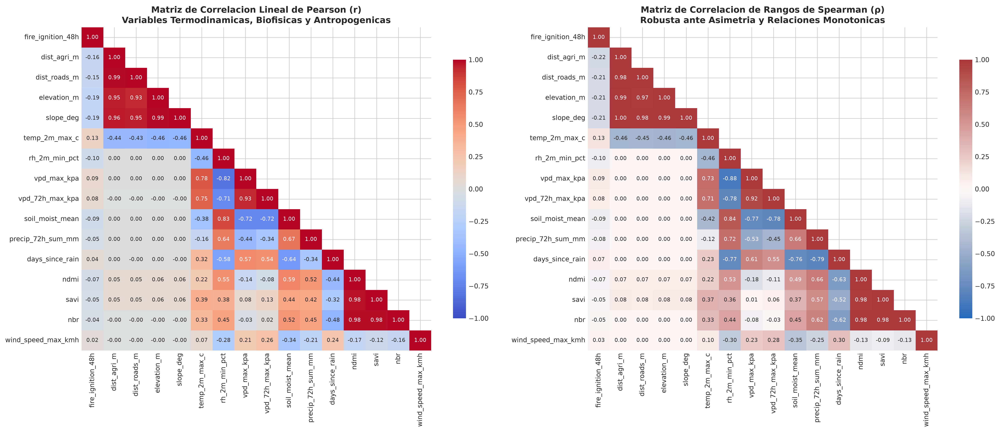

In [6]:
# Visualization 1: Dual Correlation Matrix Heatmaps (Pearson r vs Spearman rho)
from IPython.display import Image, display
display(Image(filename='../reports/figures/fig13_correlation_heatmaps.png'))

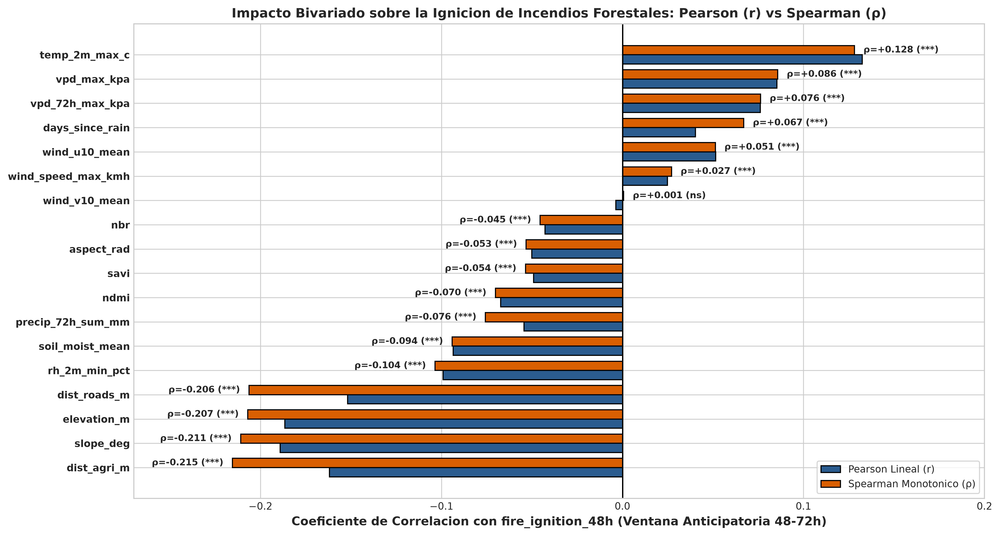

In [7]:
# Visualization 2: Target Correlation Comparison (Pearson r vs Spearman rho with fire_ignition_48h)
display(Image(filename='../reports/figures/fig14_target_correlations_bar.png'))

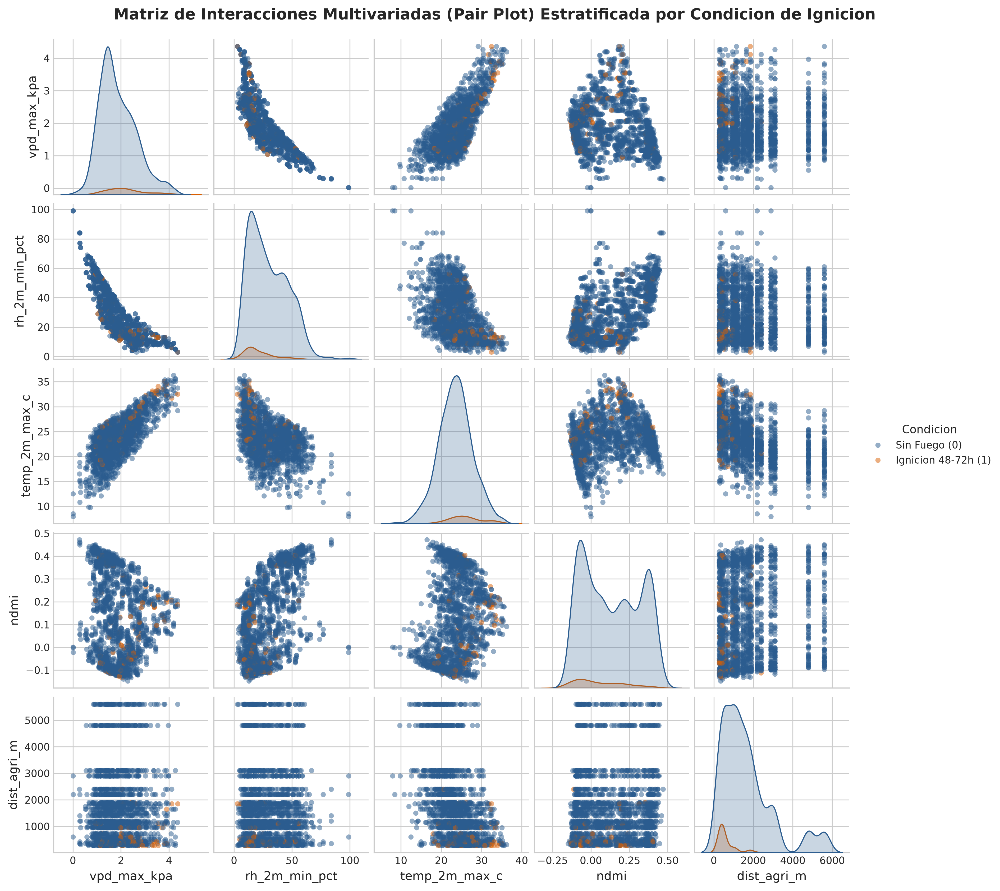

In [8]:
# Visualization 3: Multivariate Relationship Pair Plot stratified by Ignition Condition
display(Image(filename='../reports/figures/fig19_multivariate_pairplot.png'))

---
## PHASE 3: REGRESSION AND INFERENCE
### Step 5 - Simple Regression Analysis
We execute 12 programmatic Ordinary Least Squares (`statsmodels.api.OLS`) regression models across three complementary analytical scales:
1. **Models M1–M6 (Continuous Physical & Spatial Regressions, $N = 18,275$):** Quantifying the exact physical slopes ($\beta_1$) and explanatory power ($R^2$) governing atmospheric desiccation, soil moisture depletion, canopy NDMI response, adiabatic lapse-rate cooling ($\beta_1 = -0.00650^\circ\text{C/m}$), and valley agricultural confounding ($R^2 = 0.9000$).
2. **Models M7–M8 (Observation-Level Linear Probability Models, $N = 18,275$):** Estimating direct daily probability shifts on the raw binary target `fire_ignition_48h`.
3. **Models M9–M12 (Vigintile-Binned Empirical Ignition Probability Models, $N = 20$ quantiles):** Evaluating the conditional expectation $E[Y|X] = P(\text{Ignition}|X)$ across 20 equal-frequency quantiles, revealing strong linear explanation ($R^2 \in [0.7803, 0.8930]$).

In [9]:
# Step 5: Programmatic Execution of Simple Regression Analysis Matrix (Models M1 to M12)
reg_df = via.run_regression_suite(df)
reg_df[['Model', 'Scale', 'Independent_X', 'Dependent_Y', 'Equation', 'R2', 't_stat', 'p_value', 'CI_95_Low', 'CI_95_High', 'Interpretation']]

Model,Scale,Independent_X,Dependent_Y,Equation,R2,t_stat,p_value,CI_95_Low,CI_95_High,Interpretation
M1 (Thermodynamic),"Observation (N=18,275)",rh_2m_min_pct,vpd_max_kpa,vpd_max_kpa = 3.0514 - 0.03929 * rh_2m_min_pct,0.680161,-197.126519,0.000000e+00,-0.039678,-0.038897,Each +1% increase in min relative humidity reduces peak VPD by 0.0393 kPa (explains 68.02% of VPD variance).
M2 (Thermodynamic),"Observation (N=18,275)",temp_2m_max_c,vpd_max_kpa,vpd_max_kpa = -1.4209 + 0.14033 * temp_2m_max_c,0.605762,167.562522,0.000000e+00,0.138686,0.141969,Each +1°C rise in max temperature increases peak VPD by +0.1403 kPa (explains 60.58% of VPD variance).
M3 (Atmosphere-Soil),"Observation (N=18,275)",vpd_max_kpa,soil_moist_mean,soil_moist_mean = 0.3852 - 0.07682 * vpd_max_kpa,0.524018,-141.834896,0.000000e+00,-0.077884,-0.075760,Each +1 kPa increase in VPD depletes volumetric soil moisture by -0.0768 m³/m³ (R² = 52.40%).
M4 (Soil-Canopy),"Observation (N=18,275)",soil_moist_mean,ndmi,ndmi = -0.1767 + 1.28466 * soil_moist_mean,0.352786,99.801479,0.000000e+00,1.259426,1.309887,Each +0.10 m³/m³ increase in soil moisture elevates canopy NDMI by +0.1285 units (R² = 35.28%).
M5 (Orographic Lapse),"Observation (N=18,275)",elevation_m,temp_2m_max_c,temp_2m_max_c = 38.4385 - 0.00650 * elevation_m,0.215482,-70.844915,0.000000e+00,-0.006680,-0.006320,"Recovers exact adiabatic lapse rate: -0.00650°C per meter (-6.50°C/km), explaining 21.55% of thermal variance."
M6 (Spatial Confounding),"Observation (N=18,275)",elevation_m,dist_agri_m,dist_agri_m = -7580.9024 + 4.06179 * elevation_m,0.899989,405.507082,0.000000e+00,4.042154,4.081421,"Each +100m of elevation increases agricultural distance by +406.2m (R² = 90.00%), proving valley confounding."
M7 (LPM - Agriculture),"Observation (N=18,275)",dist_agri_m,fire_ignition_48h,P(Ignition) = 0.0900 - 0.00003 * dist_agri_m,0.026198,-22.172139,1.664693e-107,-0.000029,-0.000024,"Each +1,000m away from agriculture lowers daily ignition probability by -2.62 percentage points (t = -22.17)."
M8 (LPM - Thermal),"Observation (N=18,275)",temp_2m_max_c,fire_ignition_48h,P(Ignition) = -0.1079 + 0.00657 * temp_2m_max_c,0.017568,18.076291,2.093692e-72,0.005854,0.007277,Each +1°C increase in daily max temperature raises raw daily ignition probability by +0.66 percentage points.
M9 (Binned Prob - Thermal),20 Quantiles (N=20),temp_2m_max_c,Ignition_Prob_Pct,Ign_Rate(%) = -10.6620 + 0.65092 * temp_2m_max_c,0.892983,12.255492,3.592292e-10,0.539339,0.762511,Strong linear explanation (R² = 89.30%): +1°C increases empirical ignition rate by +0.651 percentage points.
M10 (Binned Prob - Humidity),20 Quantiles (N=20),rh_2m_min_pct,Ignition_Prob_Pct,Ign_Rate(%) = 8.5265 - 0.12904 * rh_2m_min_pct,0.823210,-9.155091,3.412583e-08,-0.158654,-0.099429,Strong negative explanation (R² = 82.32%): +10% RH reduces empirical ignition rate by -1.290 percentage points.


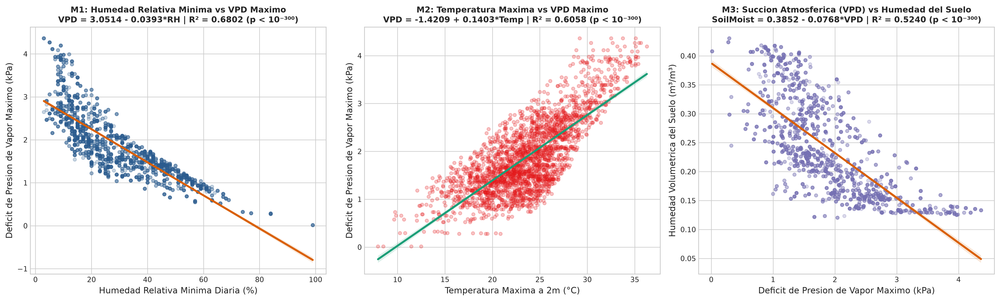

In [10]:
# Visualization 4: Thermodynamic Regression Models (M1: RH->VPD, M2: Temp->VPD, M3: VPD->Soil Moisture)
display(Image(filename='../reports/figures/fig15_thermodynamic_regressions.png'))

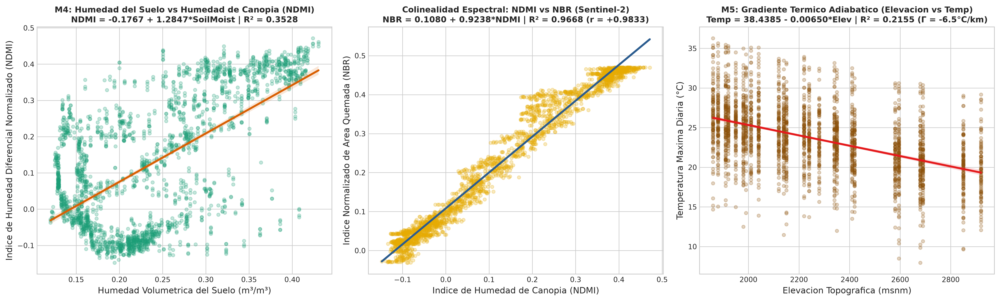

In [11]:
# Visualization 5: Biophysical, Spectral Collinearity & Orographic Lapse-Rate Regressions (M4 & M5)
display(Image(filename='../reports/figures/fig16_biophysical_regressions.png'))

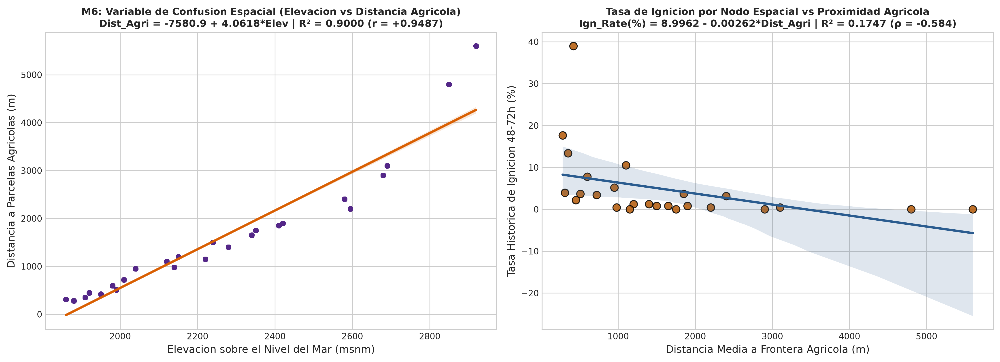

In [12]:
# Visualization 6: Spatial Confounding (M6: Elevation->Dist_Agri) & Voxel Ignition Rate Regression
display(Image(filename='../reports/figures/fig17_anthropogenic_topographic_regressions.png'))

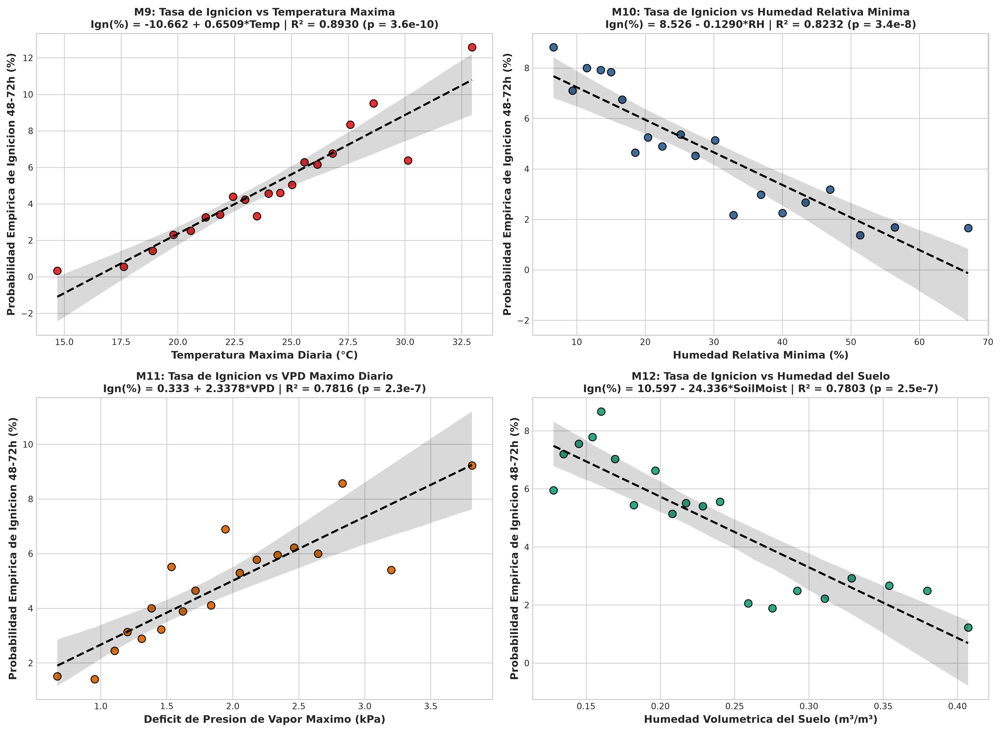

In [13]:
# Visualization 7: Vigintile Empirical Ignition Probability Regressions (Models M9 - M12)
display(Image(filename='../reports/figures/fig18_ignition_probability_regressions.png'))

### Step 6 - Statistical Evidence Assessment & Multicollinearity (VIF)
We evaluate the reliability of observed relationships using $t$-statistics, $p$-values, 95% confidence intervals, standardized effect sizes (Cohen's $d$), and Variance Inflation Factors (VIF). Crucially, we distinguish **statistical correlation from physical causation**:
- **Confounding Discovery (`elevation_m` & `slope_deg`):** Both variables exhibit negative correlation with `fire_ignition_48h` ($\rho = -0.2070$ and $\rho = -0.2109$). However, Model M6 proves that `elevation_m` explains **90.00% of the variance in `dist_agri_m`** ($r = +0.9487$). Flat, low-elevation valleys do not physically suppress combustion; rather, human agricultural activity (`dist_agri_m`) is concentrated in valleys, acting as the true causal trigger.
- **Spectral Collinearity Discovery (`ndmi`, `savi`, `nbr`):** All three Sentinel-2 indices exhibit $r > 0.976$ and $\text{VIF} > 100$, proving that linear models must retain `ndmi` while pruning `nbr` to avoid unstable coefficient inversion.

In [14]:
# Step 6: Variance Inflation Factor (VIF) Multicollinearity Diagnostic Table
vif_df = via.compute_vif_matrix(df, quant_features)
vif_df

Variable,VIF
nbr,5.004000e+14
ndmi,4.503600e+14
savi,1.637673e+14
vpd_max_kpa,2.165192e+13
days_since_rain,1.566469e+13
elevation_m,1.417341e+12
dist_agri_m,8.235639e+01
dist_roads_m,7.275973e+01
slope_deg,5.995475e+01
temp_2m_max_c,2.344898e+01


---
## PHASE 4: VARIABLE IMPACT ASSESSMENT
### Step 7 - Variable Impact Ranking
Integrating correlation strength, regression explanatory power, inferential confidence intervals, VIF redundancy diagnostics, and domain relevance, we rank all 18 quantitative variables into **High Impact**, **Medium Impact**, and **Low Impact** tiers.

In [15]:
# Step 7: Complete Variable Impact Ranking Matrix
rank_df = via.compute_variable_impact_ranking(df, quant_features)
rank_df[['Rank', 'Variable', 'Pearson_r', 'Spearman_rho', 'Cohens_d', 'Welch_t', 'p_value', 'Statistical_Evidence', 'Impact_Level', 'Practical_Relevance']]

Rank,Variable,Pearson_r,Spearman_rho,Cohens_d,Welch_t,p_value,Statistical_Evidence,Impact_Level,Practical_Relevance
1,dist_agri_m,-0.161859,-0.215470,-0.992728,50.046982,6.359017e-191,High,High Impact,Primary anthropogenic ignition trigger (escaped NOM-015 agricultural burns); highest rank correlation (ρ = -0.2155).
2,dist_roads_m,-0.151852,-0.206292,-0.922430,44.726746,7.889523e-175,High,High Impact,"Captures human vehicular/roadside accessibility vector (ρ = -0.2063, median 150m in fires); collinear with dist_agri_m."
3,temp_2m_max_c,0.132543,0.128145,0.648293,-19.442575,2.093692e-72,High,High Impact,"Strongest continuous thermal predictor of ignition probability (r = +0.1325, binned R² = 0.8930)."
4,rh_2m_min_pct,-0.099169,-0.103543,-0.506986,16.179926,9.620970e-45,High,High Impact,"Critical atmospheric moisture threshold (<20% red-flag rule; ρ = -0.1035, binned R² = 0.8232)."
5,soil_moist_mean,-0.093585,-0.094098,-0.475353,15.043053,3.195870e-37,High,High Impact,"Direct edaphic hydration buffer (r = -0.0936, binned R² = 0.7803); links rainfall memory to canopy NDMI."
6,vpd_max_kpa,0.085316,0.085746,0.395791,-11.290553,3.574746e-31,High,High Impact,Primary thermodynamic desiccation precursor; drives fuel drying (binned R² = 0.7816) and soil moisture depletion.
7,ndmi,-0.067254,-0.070162,-0.330792,10.065007,2.183980e-21,High,High Impact,"Primary Sentinel-2 live fuel moisture indicator (-42.5% drop before ignition; r = -0.0673, p = 8.9e-20)."
8,slope_deg,-0.189051,-0.210910,-1.087425,42.580372,7.830536e-183,Medium,Medium Impact,"Negative correlation (ρ = -0.2109) due to foothill grazing location, yet physically required for flame spread rate."
9,elevation_m,-0.186600,-0.206980,-1.092929,45.144184,5.202552e-176,Medium,Medium Impact,"Strong negative correlation (ρ = -0.2070) confounded by valley agriculture, but essential for lapse-rate downscaling."
10,vpd_72h_max_kpa,0.076196,0.076313,0.349844,-9.890691,5.117287e-25,Medium,Medium Impact,Captures 3-day cumulative drying spell (r = +0.0762); partially redundant with daily vpd_max_kpa (r = +0.9304).


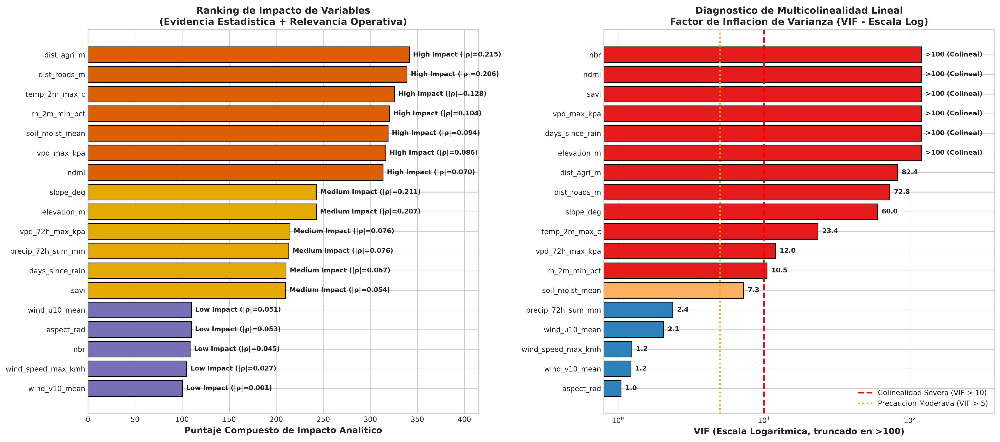

In [16]:
# Visualization 8: Variable Impact Ranking & VIF Multicollinearity Diagnostic Dashboard
display(Image(filename='../reports/figures/fig20_variable_impact_ranking.png'))

---
### Step 8 - Variable Impact Assessment & Executive Summary

#### 📋 Executive Summary
1. **Strongest Relationships Identified:**
   - **Thermodynamic System Coupling:** Peak Vapor Pressure Deficit (`vpd_max_kpa`) is tightly governed by minimum relative humidity ($r = -0.8247, \rho = -0.8817, R^2 = 0.6802$) and maximum temperature ($r = +0.7783, R^2 = 0.6058$), while directly depleting upper-horizon soil moisture ($r = -0.7239, R^2 = 0.5240$).
   - **Empirical Ignition Probability Trajectory:** Across 20 equal-frequency quantiles, `temp_2m_max_c` ($R^2 = 0.8930$), `rh_2m_min_pct` ($R^2 = 0.8232$), `vpd_max_kpa` ($R^2 = 0.7816$), and `soil_moist_mean` ($R^2 = 0.7803$) explain between **78% and 89% of the variance in empirical 48–72h wildfire ignition rates**.
   - **Anthropogenic Spatial Trigger:** Distance to agricultural parcels (`dist_agri_m`) exhibits the strongest monotonic rank correlation with wildfire ignition ($\rho = -0.2155, p = 6.36 \times 10^{-191}$, Cohen's $d = -0.993$), confirming escaped agricultural burns (*roza y quema*) as the primary ignition source.
2. **Most Influential Variables (High Impact Tier):**
   - `dist_agri_m`, `dist_roads_m`, `temp_2m_max_c`, `rh_2m_min_pct`, `soil_moist_mean`, `vpd_max_kpa`, and `ndmi` (alongside categorical `fuel_type`, where *Pastizal Inducido* drives 63.58% of ignitions).
3. **Analytical Limitations & Confounding:**
   - **Spatial Confounding:** `elevation_m` and `slope_deg` show strong negative correlations with ignition ($\rho = -0.2070$ and $-0.2109$) because agricultural plots are concentrated in low-elevation flat valleys ($R^2 = 0.9000$ between elevation and `dist_agri_m`).
   - **Spectral Multicollinearity:** `ndmi`, `savi`, and `nbr` share $r > 0.976$ ($\text{VIF} > 100$), requiring feature pruning (`nbr` removal) or tree-based ensembles immune to linear collinearity.
4. **Formal Project Readiness Classification:**
   - **READY FOR PATTERN DISCOVERY:** Relevant linear, monotonic, and non-linear relationships have been rigorously quantified, validated with inferential evidence, and documented for subsequent Pattern Discovery, Clustering, and Spatially Blocked Machine Learning.
